In [2]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW
col_dict = {0: 'red', 1: 'blue', 2: 'green', 3: 'orange', 4:'purple', 5:'black', 6:'yellow', 7:'pink', 8:'lightblue',9:'lime', 10:'sienna',11:'indigo'}

In [3]:
def VEM_SBM_best(A, Xg=None, Xc=None, K=2, n_restarts=20, base_seed=0, max_iter=200, tol = 1e-6,verbose=False):
    best = None
    best_seed = None
    for s in range(base_seed, base_seed + n_restarts):
        np.random.seed(s)
        fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=200, tol = 1e-6, verbose=False)
        if best is None or fit['ELBO'][-1] > best['ELBO'][-1]:
            best = fit
            best_seed = s
    best['seed'] = best_seed
    return best

In [4]:
df = pd.read_csv('Airbnb_rome.csv')
df = df[df.last_review.notna()]
df['year'] = df.last_review.apply(lambda x: int(x.split('-')[0]))
df['month'] = df.last_review.apply(lambda x: int(x.split('-')[1]))
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,year,month
0,2737,"Elif's room in cozy, clean flat.",3047,Elif,NaN,VIII Appia Antica,41.871360,12.482150,Private room,68.0,31,5,2015-05-08,0.04,6,365,0,NaN,2015,5
1,3079,Cozy apartment (2-4)with Colisseum view,3504,Laura,NaN,I Centro Storico,41.895000,12.491170,Entire home/apt,140.0,31,21,2022-04-30,0.12,6,334,0,NaN,2022,4
2,11834,"Charming Boschetto Studio, Rome",44552,Serena,NaN,I Centro Storico,41.895447,12.491181,Entire home/apt,130.0,2,283,2025-06-19,1.64,1,208,37,IT058091C29VJSIZQZ,2025,6
3,12398,Casa Donatello - Home far from Home,11756,Gea,NaN,II Parioli/Nomentano,41.925820,12.469280,Entire home/apt,203.0,31,85,2025-06-29,0.47,1,115,13,it058091c2kv6epw8f,2025,6
4,19965,*S.Peter's Square 5Min ON FOOT 2 bedrooms*,75450,Sabrina,NaN,I Centro Storico,41.907310,12.453500,Entire home/apt,162.0,3,173,2025-06-16,1.06,3,240,25,IT058091C20YD35BX2,2025,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36294,1439970978838531463,Domus Diamond - Luxury Apartment,457919940,Simone,NaN,XII Monte Verde,41.867160,12.442511,Entire home/apt,75.0,2,3,2025-06-29,3.00,2,237,3,IT058091C2VKWWHS3S,2025,6
36296,1440294970820890977,Archouse - Elegante appartamento,1561753,Valentina,NaN,I Centro Storico,41.890222,12.513229,Entire home/apt,168.0,2,1,2025-06-15,1.00,2,327,1,IT058091C22TXTJ7NA,2025,6
36298,1440335673772336036,Trastevere Loft With Balcony,14828708,Marco,NaN,I Centro Storico,41.890320,12.473820,Entire home/apt,275.0,3,1,2025-06-21,1.00,15,26,1,"I applied for a CIN, but haven’t received it yet",2025,6
36299,1440392934846388811,Grandpa’s house,700435567,Marco,NaN,VII San Giovanni/Cinecittà,41.864683,12.569607,Entire home/apt,85.0,2,2,2025-06-25,2.00,1,355,2,IT058091B43YIJ92A5,2025,6


## Prova 2023

In [5]:
df2 = df[(df.year==2023)]
ok_cols = ['latitude', 'longitude' ,'price', 'minimum_nights', 'number_of_reviews','availability_365','neighbourhood','room_type']
df2 = df2[ok_cols]
df2 = df2[df2.notna().all(axis=1)]
df2

,latitude,longitude,price,minimum_nights,number_of_reviews,availability_365,neighbourhood,room_type
9,41.910290,12.447030,153.0,2,16,166,I Centro Storico,Private room
18,42.057450,12.486990,94.0,31,15,364,XV Cassia/Flaminia,Entire home/apt
41,41.912477,12.442726,115.0,2,26,79,XIV Monte Mario,Entire home/apt
63,41.725690,12.286990,429.0,3,15,344,X Ostia/Acilia,Entire home/apt
64,41.927350,12.509150,109.0,3,14,168,II Parioli/Nomentano,Private room
...,...,...,...,...,...,...,...,...
20650,41.898556,12.517948,155.0,1,2,95,II Parioli/Nomentano,Entire home/apt
20874,41.868575,12.546464,116.0,2,1,0,V Prenestino/Centocelle,Entire home/apt
21077,41.874192,12.487115,257.0,1,2,240,I Centro Storico,Entire home/apt
21101,41.910025,12.520885,77.0,1,1,244,II Parioli/Nomentano,Private room


In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

n = len(df2)
lats = df2['latitude'].values
lons = df2['longitude'].values

dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(i+1, n):
        d = haversine_km(lats[i], lons[i], lats[j], lons[j])
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d

threshold_km = 0.2
A = (dist_matrix <= threshold_km).astype(int)
np.fill_diagonal(A, 0)

n_edges = int(A.sum() / 2)
n_isolated = int((A.sum(axis=1) == 0).sum())
print(f'n = {n}, edges = {n_edges}, isolated = {n_isolated}')

n = 1093, edges = 2385, isolated = 259


In [7]:
lat_min, lat_max = 41.860, 41.925
lon_min, lon_max = 12.430, 12.530

df3 = df2[(df2['latitude'] >= lat_min) & (df2['latitude'] <= lat_max) &
        (df2['longitude'] >= lon_min) & (df2['longitude'] <= lon_max)]
df3 = df3.reset_index(drop=True)

In [8]:
n = len(df3)
lats = df3['latitude'].values
lons = df3['longitude'].values

dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(i+1, n):
        d = haversine_km(lats[i], lons[i], lats[j], lons[j])
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d

threshold_km = 0.4
A = (dist_matrix <= threshold_km).astype(int)
np.fill_diagonal(A, 0)

n_edges = int(A.sum() / 2)
n_isolated = int((A.sum(axis=1) == 0).sum())
print(f'n = {n}, edges = {n_edges}, isolated = {n_isolated}')

n = 793, edges = 6984, isolated = 13


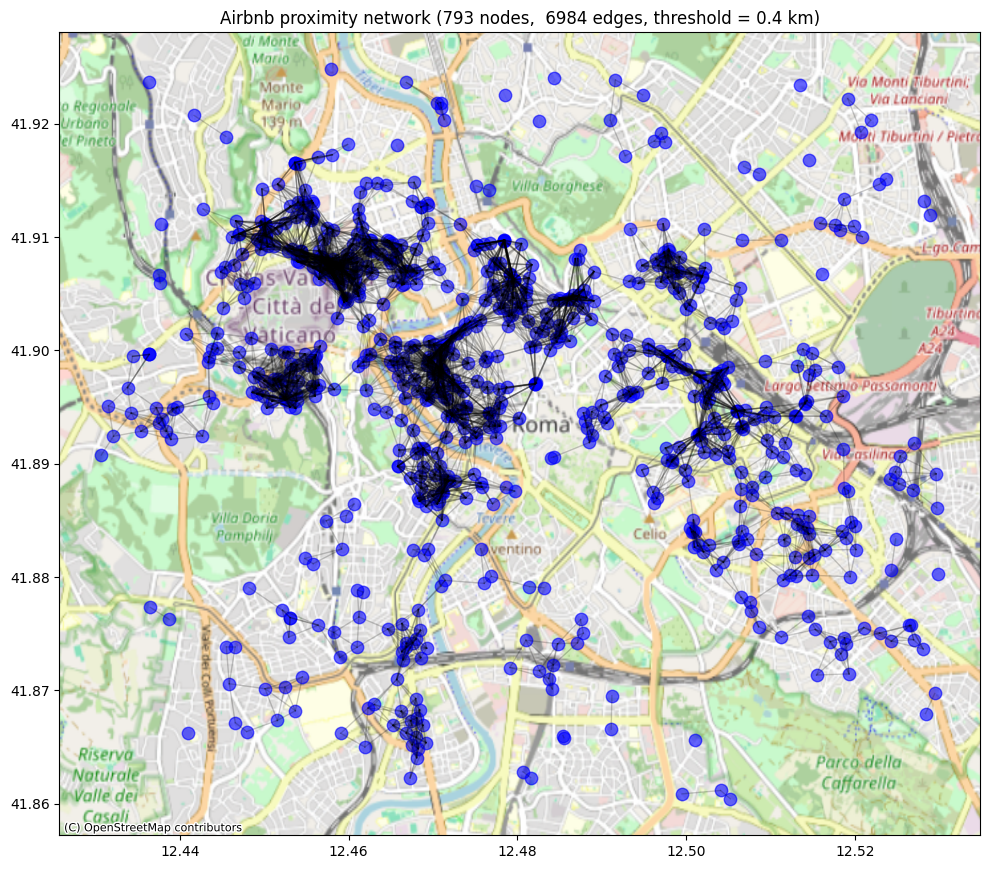

In [23]:
G = nx.from_numpy_array(A)


gdf = gpd.GeoDataFrame(df3, geometry=gpd.points_from_xy(df3['longitude'], df3['latitude']), crs='EPSG:4326')

ax = gdf.plot(color='blue', markersize=80, alpha=0.6, figsize=(10, 10))

try:
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf.crs)
except Exception:
    pass  # basemap tiles may be unavailable in some environments

for i, j in G.edges():
    x_values = [gdf.geometry.iloc[i].x, gdf.geometry.iloc[j].x]
    y_values = [gdf.geometry.iloc[i].y, gdf.geometry.iloc[j].y]
    ax.plot(x_values, y_values, color='black', lw=1, alpha=0.2)

#plt.axis('off')
plt.title(f'Airbnb proximity network ({n} nodes,  {n_edges} edges, threshold = {threshold_km} km)')
plt.tight_layout()
plt.show()

In [10]:
Xg = df3.iloc[:,2:6]
Xc = df3.iloc[:,6:]

In [11]:
neighbourhood_relabel = {}
for i, neig in enumerate(Xc.neighbourhood.unique()):
    neighbourhood_relabel[neig] = i

roomtype_relabel = {}
for i, room in enumerate(Xc.room_type.unique()):
    roomtype_relabel[room] = i

In [12]:
Xc['neigh_relabel'] = Xc.neighbourhood.map(neighbourhood_relabel)
Xc['room_relabel'] = Xc.room_type.map(roomtype_relabel)

In [18]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5,6,7]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc[['neigh_relabel','room_relabel']], K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5
6
7


In [13]:
import pickle

# with open('Rs_results_airbnb2023.pkl', 'wb') as f:
#     pickle.dump(Rs, f)

with open('Rs_results_airbnb2023.pkl', 'rb') as f:
    Rs = pickle.load(f)

In [15]:
Ks = [2,3,4,5,6,7]

for K in Ks:
    print(Rs[K]['vICL'])

-54240.58910371408
-49189.2151272112
-49057.395063898344
-47954.202021358506
-48537.672817174185
-48013.09858070532


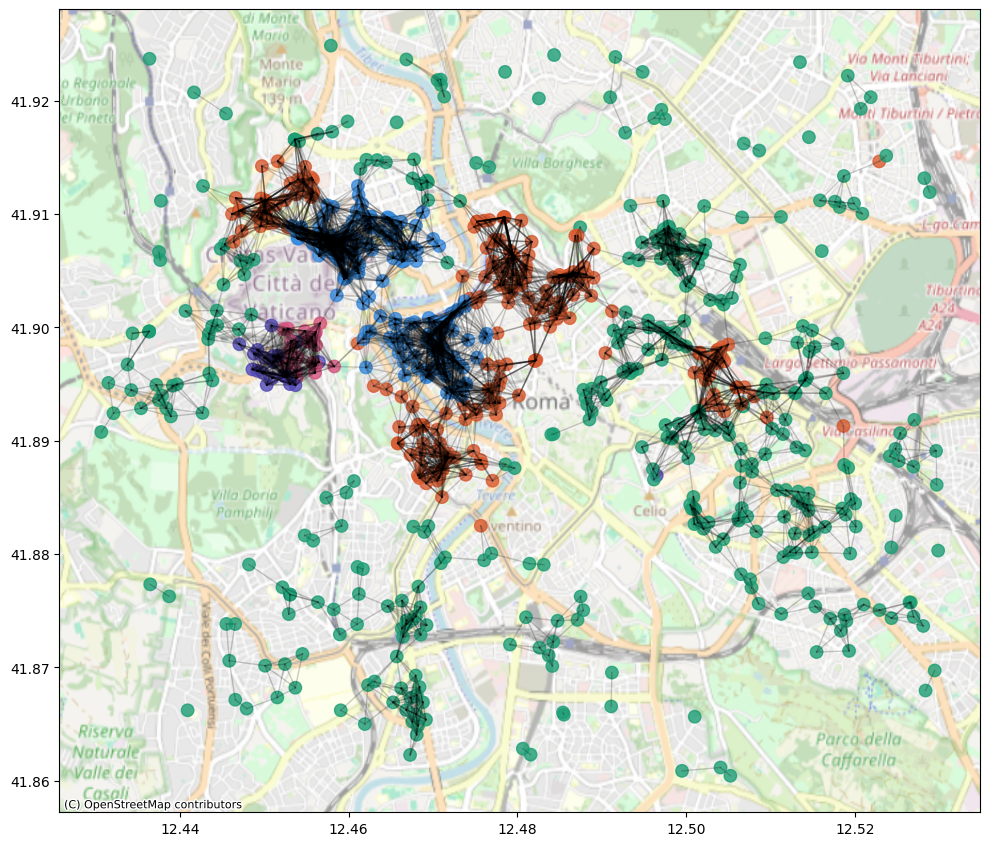

In [21]:
partition = np.argmax(Rs[5]['r'], axis=1)

colors = ['#534AB7', '#1D9E75', '#D85A30', '#D4537E', '#378ADD', '#639922', '#BA7517']
node_colors = [colors[k] for k in partition]

ax = gdf.plot(color=node_colors, markersize=80, alpha=0.8, figsize=(10, 10))

try:
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf.crs, alpha=0.7)
except Exception:
    pass  # basemap tiles may be unavailable in some environments

for i, j in G.edges():
    x_values = [gdf.geometry.iloc[i].x, gdf.geometry.iloc[j].x]
    y_values = [gdf.geometry.iloc[i].y, gdf.geometry.iloc[j].y]
    ax.plot(x_values, y_values, color='black', lw=1, alpha=0.2)

#plt.axis('off')
#plt.title(f'Airbnb proximity network ({n} nodes,  {n_edges} edges, threshold = {threshold_km} km)')
plt.tight_layout()
plt.show()

In [31]:
dtemp = df3.copy()
dtemp['cluster'] = partition

In [33]:
dtemp.columns

Index(['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'availability_365', 'neighbourhood', 'room_type', 'cluster'],
      dtype='object')

In [34]:
dtemp.groupby('cluster')[['price', 'minimum_nights', 'number_of_reviews',
       'availability_365']].mean()

,price,minimum_nights,number_of_reviews,availability_365
cluster,,,,
0,208.681818,14.136364,24.227273,242.681818
1,178.981912,8.149871,20.379845,229.844961
2,412.384615,4.884615,19.096154,228.250000
3,183.428571,2.142857,5.000000,220.619048
4,311.116129,7.006452,16.670968,223.483871


In [34]:
dU = pd.DataFrame(Rs[5]['r'])
dU

,0,1,2,3,4
0,2.981531e-93,2.032659e-16,1.000000e+00,3.049620e-70,2.826547e-27
1,3.107009e-28,1.000000e+00,2.388097e-10,3.194901e-30,2.718949e-12
2,1.208830e-39,1.000000e+00,2.498596e-22,0.000000e+00,1.609392e-40
3,6.163832e-50,9.999947e-01,5.252305e-06,0.000000e+00,2.157097e-28
4,5.801076e-99,1.578253e-25,1.000000e+00,2.998134e-81,1.703748e-28
...,...,...,...,...,...
788,8.277445e-34,1.000000e+00,4.998032e-24,7.239734e-40,1.354957e-27
789,1.476436e-120,6.050335e-34,1.000000e+00,0.000000e+00,1.300035e-32
790,2.042247e-29,1.000000e+00,1.308528e-12,6.222149e-37,2.266522e-24
791,1.066686e-26,1.000000e+00,4.252872e-10,1.614946e-33,3.483367e-20


In [43]:
dU['max'] = dU.to_numpy().max(axis=1)
dU[dU['max']<0.8]      # fuzzy ones

,0,1,2,3,4,max
137,1.284763e-40,0.699527,0.300473,1.277247e-29,4.648774e-12,0.699527
192,3.044621e-74,0.560864,0.439136,5.514270e-83,1.536587e-31,0.560864
